# Data Science Consultancy for Mr. Grapeglamour's Winery Revamp

## Background
Mr. Gaurav Grapeglamour, a prominent wine baron, has engaged your consulting company to modernize his traditional wineries and distribution systems.

As part of this engagement, you will use the **Red Wine Quality dataset** (available on Google Drive: https://drive.google.com/file/d/175z080Ki2e_7jhLG72kVHos4Q_2ZoJOQ/view?usp=drive_link) to analyze and classify the quality of his red wines. By applying data science techniques, the goal is to optimize processes, minimize losses, and improve overall wine quality.

*The Red Wine Quality dataset contains physicochemical properties of red wines along with their quality ratings on a scale from 0 to 10.*

##### **Homework Submission**
**Do NOT delete or modify any part of the questions when submitting, including the pre-loaded comments in the code cells.**

You may add your own comments.

Submit **this** Google Colab/Jupyter Notebook file on Gradescope.

### Part A (5 points total)
#### Your company has an inside contact at one of Mr. Grapeglamour's wineries, who has been asked to share the winery's data so that your team can develop a strategy to impress Mr. Grapeglamour. You have been asked to submit a summary of the data received.

##### Import Libraries (1 pt)
Import the following libraries (the remaining imports are provided in the next cell):
- **numpy** as *np*
- **pandas** as *pd*

In [1]:
# Import the necessary libraries
import numpy as np
import pandas as pd

In [2]:
# Make sure the required packages are installed before running these imports.
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

##### Load the Dataset (1 pt)
Load the Red Wine Quality dataset into a DataFrame named **wine_data**.

In [3]:
# Load the Red Wine Quality dataset
# ANSWER STARTS HERE
wine_data = pd.read_csv('winequality-red.csv')

##### Explore the Data (3 pts)
Begin by examining the dataset to understand its contents. Use a **single line** of code for each of the following:
- Print the number of **samples** in the dataset (a numerical value).
- Print the number of **features** in the dataset (a numerical value).
- Print the **unique** classes of the *quality* column.

In [4]:
# Display basic information about the dataset

# Number of Samples
print(f"Number of samples: {len(wine_data)}") # ANSWER HERE

# Number of Features
print(f"Number of features: {len(wine_data.columns)}") # ANSWER HERE

# Classes for wine quality
print(f"Unique classes for quality: {wine_data['quality'].unique()}") # ANSWER HERE

Number of samples: 1599
Number of features: 12
Unique classes for quality: [5 6 7 4 8 3]


### Part B (8 points total)
#### Your manager at the consulting company, Aishani Applecider, has asked you to use the data provided by Mr. Grapeglamour's winery to build a model that predicts whether a wine should be placed in the expensive wine aisle.

#### The first step is to prepare the data.

***Note: A wine is considered expensive if its quality rating is greater than 6.***

##### Data Preprocessing (2 pts)
Before building any models, the data must be cleaned.
- Handle **missing values** by **removing** the rows that contain them.

In [5]:
# Handle missing values in wine_data by removing them from the dataset
# ANSWER STARTS HERE
wine_data.dropna(inplace=True)

##### Splitting, Training, and Testing (6 pts)
In machine learning, data is typically split into separate portions so that a model can be trained on one portion and evaluated on another. This allows us to measure how well the model performs.

The training data is used to fit the model, while the testing data assesses how well the model generalizes to unseen examples.

Splitting the data helps detect overfitting and ensures the model can make accurate predictions on new data.

As a reminder, ***a wine is considered expensive if its quality rating is greater than 6.***
- Define the **features** (**X**) and the **target label** (**y**) from the dataset.

In [6]:
# Define the features (X) and the target label (y)
# ANSWER STARTS HERE
X = wine_data.drop('quality', axis=1)
y = wine_data['quality']

- **Split** the features and target labels into **training and testing sets** using a test size of **0.3**.

*Hint: Refer to the `train_test_split` [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).*

In [7]:
# Split the data into training and testing sets (approximately 1 line)
# Pass this seed as the random_state argument
seed = 42
# ANSWER STARTS HERE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=seed)

After splitting the data, standardize the feature sets so that the model is not biased by differences in the scales or units of the features. Standardization keeps the data consistent.

- **Standardize** the training and testing feature sets.

*Hint: Refer to the `StandardScaler` [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).*

In [8]:
# Standardize the feature sets (both X_train and X_test)
# ANSWER STARTS HERE
scalar = StandardScaler()
scalar.fit(X_train)

X_train_scaled = scalar.transform(X_train)
X_test_scaled = scalar.transform(X_test)

### Part C (15 points total)

#### Your promotion depends on this project, so Ms. Applecider has asked you to be thorough in your model search. Train four different classifiers: **KNN**, **Decision Tree**, **Logistic Regression**, and **Random Forest**.

##### Load Models (4 pts)
To compare algorithms in a structured way, store the models in a single collection that can be reused for k-fold cross-validation.

- **Create** a Python dictionary named **models** that maps the name of each of the **four models** to its model object.

In [9]:
# Choose classification algorithms
# ANSWER STARTS HERE
models = {
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Logistic Regression': LogisticRegression(),
    'Random Forest': RandomForestClassifier()
}

##### K-Fold Cross-Validation (8 pts)
Using the standardized feature sets, do the following:
- Using the number of folds and the `StratifiedKFold` object provided, perform **k-fold cross-validation** for **each** model.
- Print the **name** of each model along with its **cross-validation accuracy** (mean and standard deviation).

*Hint: Refer to the `cross_val_score` [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html).*

In [10]:
# Perform k-fold Cross-Validation for each model
k_folds = 5
skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

for model_name, model in models.items():
    # ANSWER STARTS HERE
    scores = cross_val_score(model, X_train_scaled, y_train, cv=skf, scoring='accuracy')
    
    print(model_name)
    print(f"Mean: {scores.mean()}")
    print(f"StDev: {scores.std()}\n")

KNN
Mean: 0.5737948430493274
StDev: 0.03948436368951199

Decision Tree
Mean: 0.584453074951954
StDev: 0.043891491768074324

Logistic Regression
Mean: 0.6103859705317104
StDev: 0.02027040920019628

Random Forest
Mean: 0.6765414798206277
StDev: 0.028306746184550844



##### Question: Which model is the most accurate based on the results above, and why? (3 pts)
ANSWER HERE: Random forest appears to be the most accurate because it has the highest mean with the second lowest standard deviation. A higher mean means the model will have better predictive accuracy and random forest has a mean value over 0.06 more than logistic regression's mean which is a fairly wide gap. A lower standard deviation would mean less variation in the prediction so the model should have a very similar predictive accuracy regardless of the data. Random forest has a standard deviation of 0.021 whcih is very similar to the lowest being logistic regression's standard deviation of 0.020. This is much lower than the other models which range between 0.03 to 0.04 so I believe random forest is the most accurate due to having the highest mean and a low standard deviation.

### Part D (12 points total)
#### Ms. Applecider has asked you to deploy all of the models and evaluate each one on the held-out test set.

##### Model Evaluation (6 pts)
Complete the following steps to evaluate each model:
- STEP 1: **Train** each model on the training data.

In [11]:
# Train each model using the training data
for model_name, model in models.items():
    # ANSWER STARTS HERE
    model.fit(X_train_scaled, y_train)

- STEP 2: Print the **accuracy** of each model along with its **name**, in the following **format**: `Accuracy of (model name): (accuracy of the model)`
- Print a **classification report** for each model showing accuracy, precision, recall, and F1-score.

*Hint: Refer to the `classification_report` [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).*

In [12]:
# Evaluate the performance of each model
for model_name, model in models.items():
    # ANSWER STARTS HERE
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"Accuracy of {model_name}: {accuracy}")
    print(classification_report(y_test, y_pred, zero_division=0.0))

Accuracy of KNN: 0.5708333333333333
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        17
           5       0.61      0.70      0.65       195
           6       0.56      0.56      0.56       200
           7       0.48      0.41      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.57       480
   macro avg       0.28      0.28      0.28       480
weighted avg       0.54      0.57      0.55       480

Accuracy of Decision Tree: 0.575
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.66      0.65      0.65       195
           6       0.57      0.59      0.58       200
           7       0.47      0.46      0.46        61
           8       0.25      0.17      0.20         6

    accu

##### Model Interpretation (6 pts)
- **Interpret** the results of the classification models. List the models that achieved the best Accuracy, Precision, Recall, and F1-score.
- Recommend the best model based on your analysis.


ANSWER HERE:

It appears that all the models had at least one class that it did not classify an entry of the test as being, likely from a lack of test data of those classes. For example, the decision tree model never predicted a wine entry as being of quality 3 and so it's evaluation metrics for that class are all 0. I decided to use the macro average of each evaluation metric even though it treats classes that were not predicted by a model as having a precision, recall, and f1-score of 0. I believe that if a model never predicts a class that could be a potential issue with using said model and is reflected in the macro averages. The best model for each metric:

Best accuracy is Random Forest with 0.67

Best precision is Random Forest with 0.38

Best recall is Random Forest with 0.35

Best f1-score is Random Forest with 0.36

Outside of random forest, all of the other models have the exact same macro average value for their evaluation metrics. Logistic regression performed the worst in precision, recall, and f1-score despite having a higher accuracy than decision trees. The decision tree model had the worst accuracy, but performed the second best in the other 3 metrics. This means accuracy does not tell the whole story and should never be the only metric used to evaluate how well a model performs. Due to the random forest model having the best score for all 4 evaluation metrics, I would recommend random forest as the best model out of these.

### Part E (10 points)

#### Mr. Grapeglamour is pleased with your consulting company's work so far, and your promotion is within reach.

#### However, he has one final question about wine quality.

##### Which 3 features in the top-performing model have the greatest effect on wine quality?
- Create a DataFrame of **feature importances**.
- **Extract**, **sort**, and **display** the **top 3** features from that DataFrame.

*Hint: Refer to the `feature_importances_` attribute in the following documentation:*

[DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier.feature_importances_)

[RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier.feature_importances_)


In [13]:
# Extract the feature importances from the most accurate model
# ANSWER STARTS HERE
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': models['Random Forest'].feature_importances_
})

feature_importance.sort_values(by='Importance', ascending=False, inplace=True)
feature_importance.head(3)

,Feature,Importance
10,alcohol,0.148264
9,sulphates,0.113340
6,total sulfur dioxide,0.104086


**Congratulations, you have been promoted!**

**You are now one of the consulting company's elite employees.**

![](https://media.giphy.com/media/JIX9t2j0ZTN9S/giphy.gif?cid=790b76111hlwamin05rcv1ujslgjh5o49haj07h4wpuvwkgz&ep=v1_gifs_search&rid=giphy.gif&ct=g)

### Data Visualization (5 points total)
The matplotlib and seaborn libraries are powerful tools for visualizing data.

They can be used to create clear, detailed graphs that are essential for data interpretation and analysis.

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

##### Visualize the Distribution of Each Feature by Quality Class (3 pts)
Using the original dataset:
- **Plot** a histogram for each feature (a for loop is recommended).
- Title each histogram "Distribution of (Feature Name) by Quality".
- Label the **axes** appropriately and display each histogram.

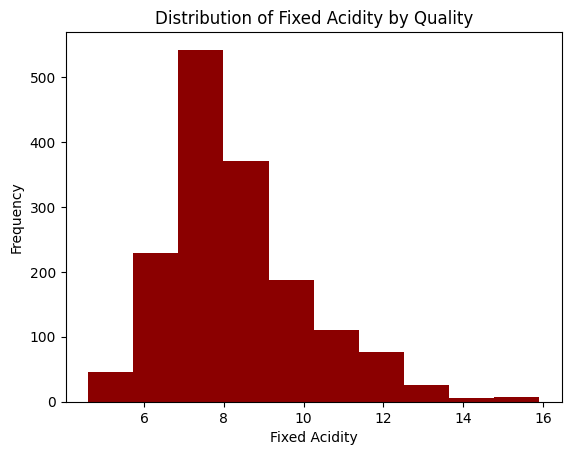

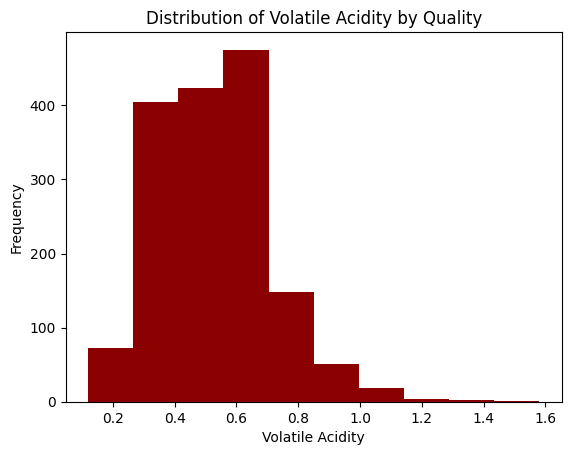

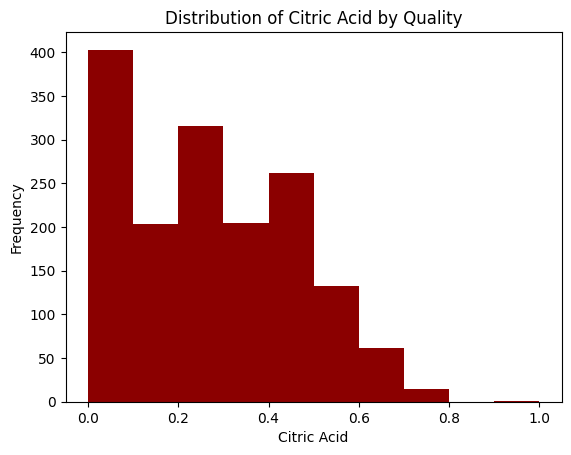

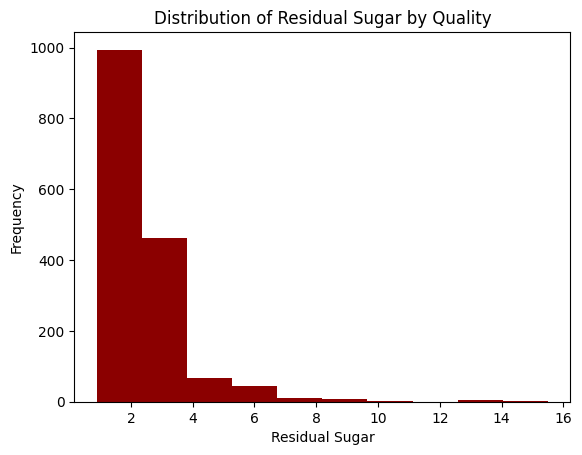

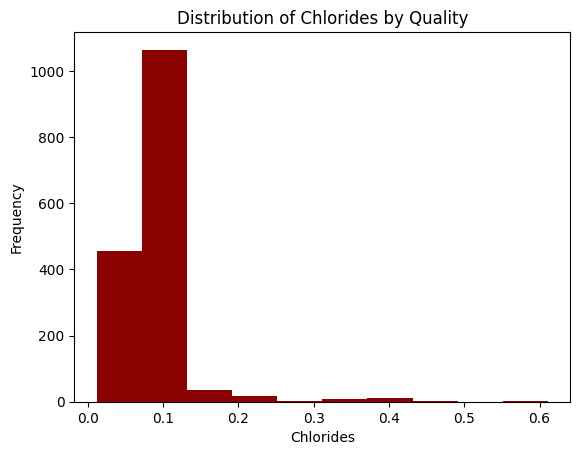

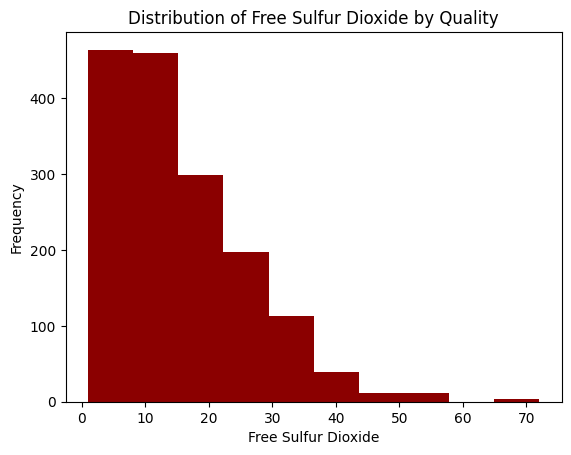

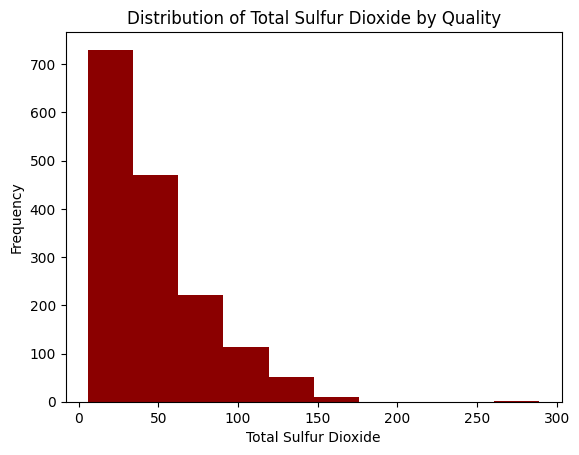

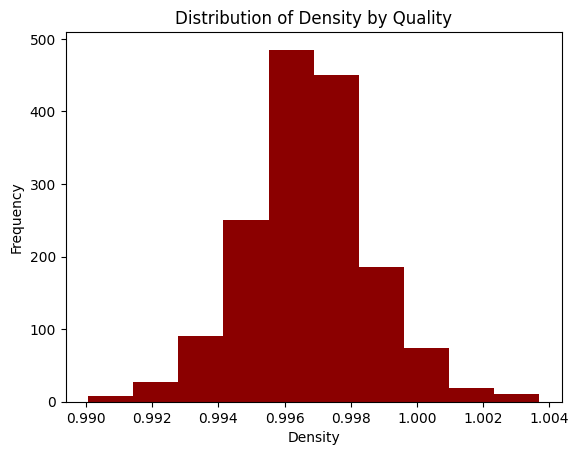

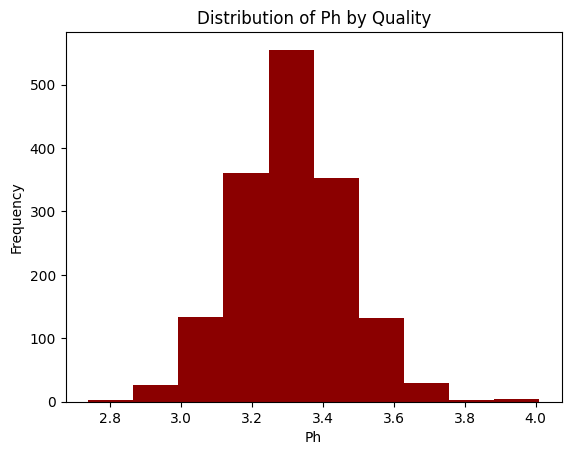

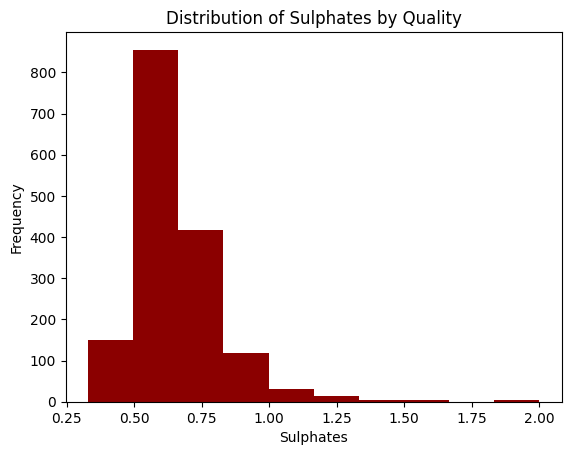

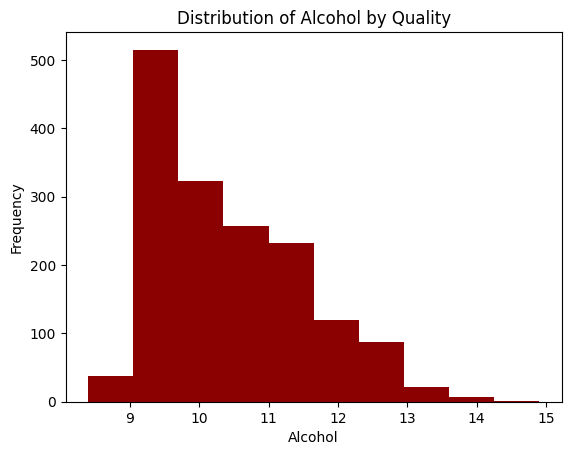

In [15]:
# Histograms for each feature
for feature in wine_data.columns[:-1]:  # Exclude the 'quality' column
    # ANSWER STARTS HERE
    plt.figure()
    plt.hist(wine_data[feature], color='darkred')

    feature = feature.title()
    plt.title(f"Distribution of {feature} by Quality")
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

##### Explore Correlations Between Features and Quality Ratings (2 pts)
- Create a **correlation matrix** showing the correlations among the features and quality.
- **Display** the matrix.

In [16]:
# Correlation Matrix
# ANSWER STARTS HERE
corr_matrix = wine_data.corr()
corr_matrix

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397
